In [5]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np

con = duckdb.connect("../olist.duckdb", read_only=True)

def run_sql(file_name):
    with open(f"../sql/{file_name}", encoding="utf-8") as f:
        query = f.read()
    return con.sql(query).df()

## 1. Revenue and number of orders per month

In [28]:
run_sql("01_monthly_revenue.sql")

,month,revenue,n_orders
0,2016-09-01,134.97,1
1,2016-10-01,40325.11,265
2,2016-12-01,10.90,1
3,2017-01-01,111798.36,750
4,2017-02-01,234223.40,1653
5,2017-03-01,359198.85,2546
6,2017-04-01,340669.68,2303
7,2017-05-01,489338.25,3546
8,2017-06-01,421923.37,3135
9,2017-07-01,481604.52,3872


<Axes: title={'center': 'Monthly revenue (delivered orders)'}, xlabel='month'>

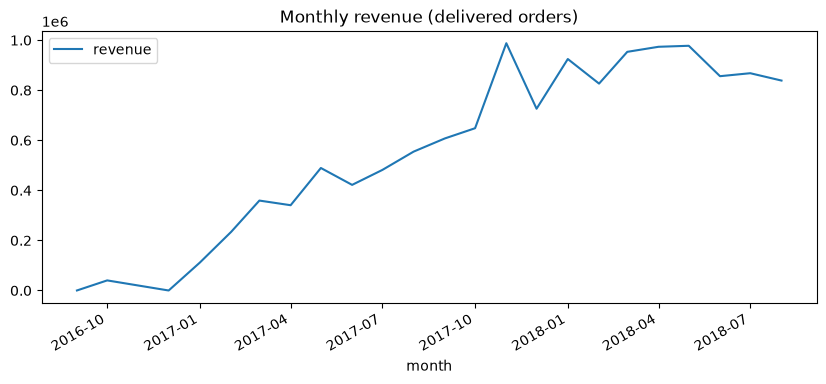

In [ ]:
monthly = run_sql("01_monthly_revenue.sql")
monthly.plot(x="month", y="revenue", figsize=(10, 4), title="Monthly revenue (delivered orders)")

In [15]:
monthly["revenue_per_order"] = (monthly["revenue"] / monthly["n_orders"]).round(2)
monthly

,month,revenue,n_orders,revenue_per_order
0,2016-09-01,134.97,1,134.97
1,2016-10-01,40325.11,265,152.17
2,2016-12-01,10.90,1,10.90
3,2017-01-01,111798.36,750,149.06
4,2017-02-01,234223.40,1653,141.70
5,2017-03-01,359198.85,2546,141.08
6,2017-04-01,340669.68,2303,147.92
7,2017-05-01,489338.25,3546,138.00
8,2017-06-01,421923.37,3135,134.58
9,2017-07-01,481604.52,3872,124.38


In [16]:
monthly["revenue_per_order"].describe()

count     23.000000
mean     133.033043
std       27.595456
min       10.900000
25%      132.165000
50%      138.000000
75%      143.985000
max      152.170000
Name: revenue_per_order, dtype: float64

- **Strong growth in 2017:** monthly delivered orders grew from 750 in January 2017 to a **peak of 7,289 in November 2017**, almost 10× in under a year.
- **November 2017 was the strongest month** in the dataset: revenue reached **R$ 988k**, **52% more revenue** (and 63% more orders) than in October 2017, most likely driven by **Black Friday** promotions.
- **From January to August 2018**, orders stayed roughly stable at about 6,000 to 7,000 per month, so growth slowed after 2017.

In [25]:
daily_nov = con.sql("""
                    SELECT 
                            DATE_TRUNC('day', orders.order_purchase_timestamp) AS day,
                            COUNT(DISTINCT orders.order_id) AS n_orders,
                            SUM(order_items.price) AS revenue
                    FROM orders
                    JOIN order_items ON orders.order_id = order_items.order_id
                    WHERE orders.order_status = 'delivered'
                                AND orders.order_purchase_timestamp >= '2017-11-01'
                                AND orders.order_purchase_timestamp < '2017-12-01'
                    GROUP BY day
                    ORDER BY n_orders desc
                    """).df()
daily_nov.head(20)

,day,n_orders,revenue
0,2017-11-24,1147,149916.58
1,2017-11-25,487,59928.51
2,2017-11-27,395,47237.27
3,2017-11-26,382,44000.48
4,2017-11-28,372,47694.76
5,2017-11-29,314,39093.09
6,2017-11-23,268,43102.33
7,2017-11-30,260,30835.85
8,2017-11-21,222,33600.85
9,2017-11-20,219,43405.98


## 2. Top 10 product categories by revenue

In [ ]:
top_categories = run_sql("02_top_categories.sql")
top_categories

,revenue,category_name,n_orders
0,1258681.34,health_beauty,8836
1,1205005.68,watches_gifts,5624
2,1036988.68,bed_bath_table,9417
3,988048.97,sports_leisure,7720
4,911954.32,computers_accessories,6689
5,729762.49,furniture_decor,6449
6,635290.85,cool_stuff,3632
7,632248.66,housewares,5884
8,592720.11,auto,3897
9,485256.46,garden_tools,3518


In [35]:
top_categories["revenue_per_order"] = (top_categories["revenue"] / top_categories["n_orders"]).round(2)
top_categories

,revenue,category_name,n_orders,revenue_per_order
0,1258681.34,health_beauty,8836,142.45
1,1205005.68,watches_gifts,5624,214.26
2,1036988.68,bed_bath_table,9417,110.12
3,988048.97,sports_leisure,7720,127.99
4,911954.32,computers_accessories,6689,136.34
5,729762.49,furniture_decor,6449,113.16
6,635290.85,cool_stuff,3632,174.91
7,632248.66,housewares,5884,107.45
8,592720.11,auto,3897,152.10
9,485256.46,garden_tools,3518,137.94


- ***Top categories*** by order numbers are bed_bath_table & health_beauty (9417 & 8836) 
- ***Watches_gifts category*** have 2nd highest revenue eventhough it has fewer orders (5624), and that includes that this category products are the ***most expensive*** with revenue per order of R$ 214 

## 3. Orders and average order value by customer state

In [ ]:
avg_order = run_sql("03_revenue_by_state.sql")
avg_order

,customer_state,avg_order_value,revenue,n_orders
0,SP,125.12,5067633.0,40501
1,RJ,142.48,1759651.0,12350
2,MG,136.73,1552482.0,11354
3,RS,136.37,728897.0,5345
4,PR,135.30,666064.0,4923
5,SC,142.98,507012.0,3546
6,BA,151.59,493584.0,3256
7,DF,142.55,296498.0,2080
8,GO,144.53,282837.0,1957
9,ES,134.66,268643.0,1995


In [18]:
avg_order['revenue_share'] = (avg_order['revenue'] / avg_order['revenue'].sum()) * 100
avg_order['revenue_share'] = avg_order['revenue_share'].round(0)
avg_order

,customer_state,avg_order_value,revenue,n_orders,revenue_share
0,SP,125.12,5067633.0,40501,38.0
1,RJ,142.48,1759651.0,12350,13.0
2,MG,136.73,1552482.0,11354,12.0
3,RS,136.37,728897.0,5345,6.0
4,PR,135.30,666064.0,4923,5.0
5,SC,142.98,507012.0,3546,4.0
6,BA,151.59,493584.0,3256,4.0
7,DF,142.55,296498.0,2080,2.0
8,GO,144.53,282837.0,1957,2.0
9,ES,134.66,268643.0,1995,2.0


- **Order volume and order value move in opposite directions.** São Paulo (SP) has the most orders (~40,000) and revenue (R$ 5.07M), but the **lowest average order value (R$ 125)**. Small north-eastern states such as Paraíba (PB) place far fewer orders (~500) but spend **74% more per order (R$ 218)**. A likely reason is that delivery to remote states is slower and more expensive, so customers there buy fewer but higher-value items.

## 4. Average delivery times in days by state

In [ ]:
delivery_time = run_sql("04_delivery_time_by_state.sql")
delivery_time

,avg_delivery_time,median_delivery_time,state,n_orders
0,8.7,7.0,SP,40494
1,11.9,10.0,MG,11354
2,11.9,10.0,PR,4923
3,12.9,11.0,DF,2080
4,14.9,13.0,SC,3546
5,15.2,12.0,RJ,12350
6,15.2,13.0,RS,5344
7,15.5,14.0,GO,1957
8,15.5,14.0,MS,701
9,15.7,14.0,ES,1995


- **Delivery time depends strongly on location.** Orders to São Paulo (SP) arrive in about **8 days** on average, while orders to remote northern states such as Amazonas (AM), Amapá (AP) and Roraima (RR) take **26 to 29 days, more than 3× longer**. These states also have very few orders (41 to 145), so the averages are less precise. Combined with the higher order values found earlier, this suggests customers in remote states buy fewer, more expensive items and wait much longer for them.

## 5. Share of orders delivered late

In [44]:
run_sql("05_orders_share_late.sql")

,delivery_status,n_orders,share_pct
0,early,88644,91.9
1,late,6534,6.8
2,on_time,1292,1.3


- **Most orders arrive before the promised date.** About **91.9%** of delivered orders arrived early, **1.3%** on the promised day, and **6.8%** (about **[6534]** orders) were late. Olist's delivery estimates are cautious, so a late order means delivery took longer than an already generous promise. The next question checks whether these late orders hurt customer reviews.

## 6. Average review score: late vs on time

In [54]:
run_sql("06_review_score.sql")

,delivery_status,n_reviews,avg_review_score
0,early,88653,4.3
1,late,6409,2.3
2,on_time,1291,4.0


- **Late deliveries are rare but very costly for satisfaction.** Only **6.7%** of reviewed orders (6,409) arrived after the promised date, but they received an average rating of **2.3 stars** versus **4.3** for early orders: **2 stars lower, almost half the score**.
- Even orders delivered exactly **on the promised day** score lower (**4.0**) than early ones, which suggests customers reward deliveries that beat the estimate. **Keeping delivery promises (or setting realistic ones) is likely one of the biggest levers for review scores.**

## 7. Share of customers with 2+ orders

In [12]:
run_sql("07_customers_share_2orders.sql")

,customer_pct
0,3.0


- Only 3.0% of customers (2,801 of 93,358) placed 2+ delivered orders, so retention of existing buyers is very low.

# 8. Payment type share

In [27]:
run_sql("08_payments_share.sql")

,n_orders,payment_pct,payment_type,avg_install
0,74304,75.31,credit_card,3.5
1,19191,19.45,boleto,1.0
2,3679,3.73,voucher,1.0
3,1485,1.51,debit_card,1.0


- Credit card is used in 75.3% of delivered orders (74,304), followed by boleto at 19.5% (19,191), voucher at 3.7% and debit card at 1.5%. Only credit card payments are split into instalments, at 3.5 on average, while the other methods are paid in a single instalment. Orders paid with several methods are counted once per method, so the shares are shares of order-method pairs

# Runing total of revenue

In [32]:
run_sql("09_running_revenue.sql")

,month,revenue,running_total
0,2016-09-01,134.97,134.97
1,2016-10-01,40325.11,40460.08
2,2016-12-01,10.90,40470.98
3,2017-01-01,111798.36,152269.34
4,2017-02-01,234223.40,386492.74
5,2017-03-01,359198.85,745691.59
6,2017-04-01,340669.68,1086361.27
7,2017-05-01,489338.25,1575699.52
8,2017-06-01,421923.37,1997622.89
9,2017-07-01,481604.52,2479227.41


**Running revenue.** Delivered-order revenue grew from almost nothing in late 2016 to a cumulative total of about 13.2 million BRL by August 2018, with a peak in November 2017 (about 988k BRL, Black Friday) and a plateau of roughly 830k to 980k per month during 2018. The very small 2016 months, and the missing November 2016, reflect the early start of the dataset, so growth rates for that period should not be over-interpreted.

In [43]:
run_sql("10_top_sellers_state.sql")

,seller_state,seller_id,revenue,n_orders,seller_rank
0,AM,327b89b872c14d1c0be7235ef4871685,1177.00,3,1
1,BA,53243585a1d6dc2643021fd1853d8905,217940.44,348,1
2,BA,c72de06d72748d1a0dfb2125be43ba63,17522.00,21,2
3,BA,75d34ebb1bd0bd7dde40dd507b8169c3,12656.33,57,3
4,CE,bbf9ad41dca6603e614efcdad7aab8c4,7846.00,14,1
5,CE,dbdd0ec73a4817971d962698f2fea022,6384.00,16,2
6,CE,8d79c8a04e42d722a75097ce5cbcf2ef,2627.82,26,3
7,DF,44073f8b7e41514de3b7815dd0237f4f,18380.64,142,1
8,DF,f3b80352b986ab4d1057a4b724be19d0,9815.10,86,2
9,DF,3c487ae8f8d7542beff5788e2e0aea83,9385.70,30,3


**Top sellers by state.** Revenue is concentrated in the largest markets: the top sellers in SP (about 227k BRL), BA (218k BRL) and RJ (123k BRL) lead their states, and in BA the leader earns more than ten times the second seller. Many small states have fewer than three sellers with delivered orders, and several top-3 sellers earn their revenue from few, high-value orders, so ranking by revenue and by order count gives different results.